Antes de comenzar a construir un modelo, lo más ideal sería explorar los datos para ganar conocimiento del negocio y los datos con los que los enfretamos

In [1]:
import pandas as pd

df = pd.read_excel("titanic3.xls")

df.head()
df = df.drop(columns=[
    "name",
    "ticket",
    "body",
    "boat",
    "home.dest",
    "cabin"
])

In [2]:
df = pd.get_dummies(df)
df.columns


Index(['pclass', 'survived', 'age', 'sibsp', 'parch', 'fare', 'sex_female',
       'sex_male', 'embarked_C', 'embarked_Q', 'embarked_S'],
      dtype='str')

# Conocer forma del dataset

La propiedad .shape, retorna una tupla que indica el número de filas y columnas que contiene el dataset

In [3]:
df.shape

(1309, 11)

In [4]:
y = df.survived
X = df.drop(columns=["survived"])
X.head(3)

,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
0,1,29.0000,0,0,211.3375,True,False,False,False,True
1,1,0.9167,1,2,151.5500,False,True,False,False,True
2,1,2.0000,1,2,151.5500,True,False,False,False,True


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.experimental import enable_iterative_imputer
from sklearn import impute
num_cols = [
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare",
    "sex_female"
]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

imputer = impute.IterativeImputer()
imputed = imputer.fit_transform(X_train[num_cols])
X_train[num_cols] = imputed
imputed = imputer.transform(X_test[num_cols])
X_test[num_cols] = imputed

In [6]:
from sklearn.preprocessing import StandardScaler

cols = [
    "age",
    "pclass",
    "sibsp",
    "fare"
]

sca = StandardScaler()
X_train[cols] = sca.fit_transform(X_train[cols])
X_test[cols] = sca.transform(X_test[cols])

En este caso , podemos leer que el dataset titanic3.xls contiene 1309 filas y 14 columnas

## Notas

Depende del autor o libro que se consulta , en un dataset a las filas se les puede conocer como
- Observaciones
- Ejemplos
- Muestras
- Instancias
- Tuplas

Mientras que a las columnas se le puede encontrar con los siguientes nombres
- Predictor
- Variables
- Atributos
- Campos

# Resumen de los datos

Usando el método .describe, podemos ver un resumen estadistico de los datos del dataset.

Hay que tener en cuenta que este método solo retorna el conteo par alos elementos no-null

In [7]:
df.describe()

,pclass,survived,age,sibsp,parch,fare
count,1309.000000,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000
mean,2.294882,0.381971,29.881135,0.498854,0.385027,33.295479
std,0.837836,0.486055,14.413500,1.041658,0.865560,51.758668
min,1.000000,0.000000,0.166700,0.000000,0.000000,0.000000
25%,2.000000,0.000000,21.000000,0.000000,0.000000,7.895800
50%,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200
75%,3.000000,1.000000,39.000000,1.000000,0.000000,31.275000
max,3.000000,1.000000,80.000000,8.000000,9.000000,512.329200


In [8]:
df.describe().iloc[:, [0, -1]]

,pclass,fare
count,1309.000000,1308.000000
mean,2.294882,33.295479
std,0.837836,51.758668
min,1.000000,0.000000
25%,2.000000,7.895800
50%,3.000000,14.454200
75%,3.000000,31.275000
max,3.000000,512.329200


# Histograma

Un histograma provee una herramienta visual potente para analizar la distribución de un campo. Pandas provee un metodo plot para generar histogramas

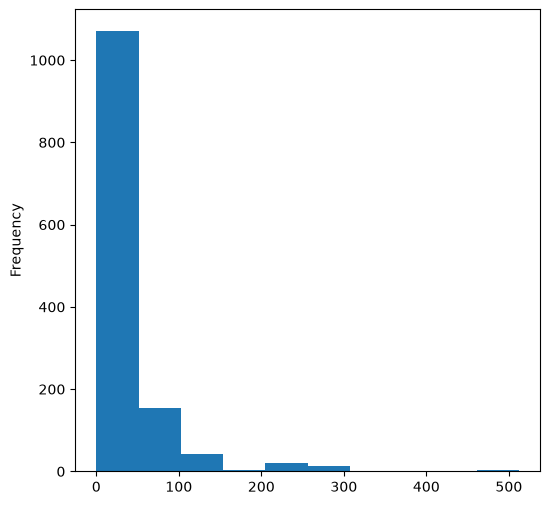

In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6,6))

X.fare.plot(kind="hist", ax=ax)
fig.savefig("images/006-faredist.png", dpi=300)

## Usando seaborn

Usando la librería SEABORN, es posible mapear  un histograma con valores continuos contra los targets

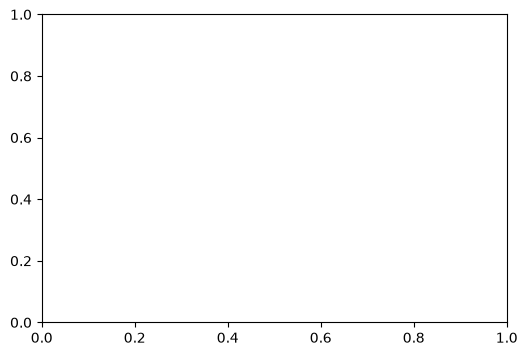

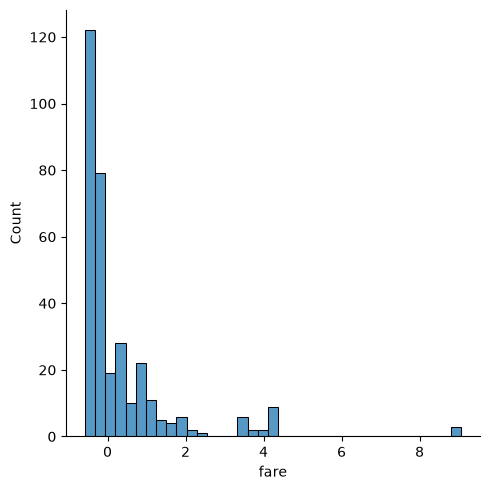

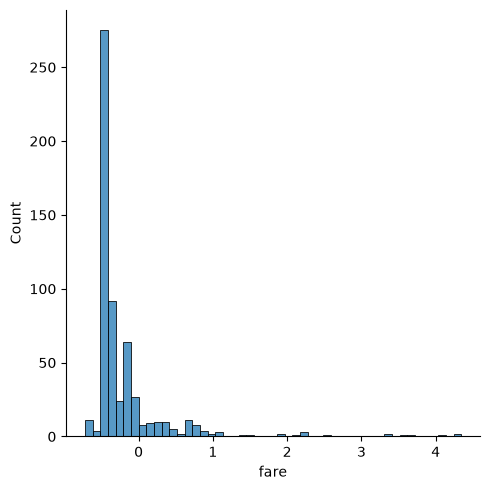

In [10]:
import seaborn as sn

fig, ax = plt.subplots(figsize=(6,4))
mask = y_train == 1

ax = sn.displot(X_train[mask].fare, label="survived")
ax = sn.displot(X_train[~mask].fare, label="died")

fig.savefig("images/006-plotfare-seaborn.png", dpi=300)

## scatterplot

Muestra una nube de puntos para representar relaciones entre dos columnas numericas

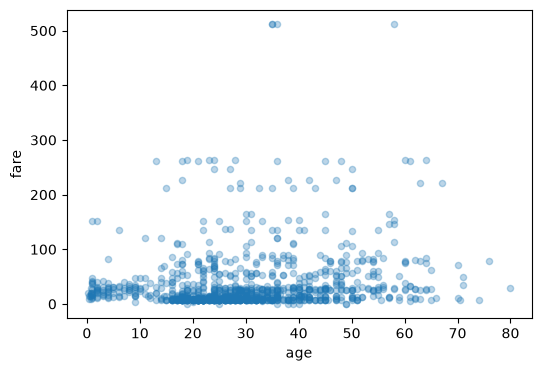

In [11]:
fig, ax = plt.subplots(figsize=(6,4))

X.plot.scatter(x="age", y="fare", ax=ax, alpha=0.3)

fig.savefig("images/006-scatter.png", dpi=300)

## Yellowbrick

la librería yellowbrick en su paquete features, implementa la clase ```JoinPlotVisualizer"


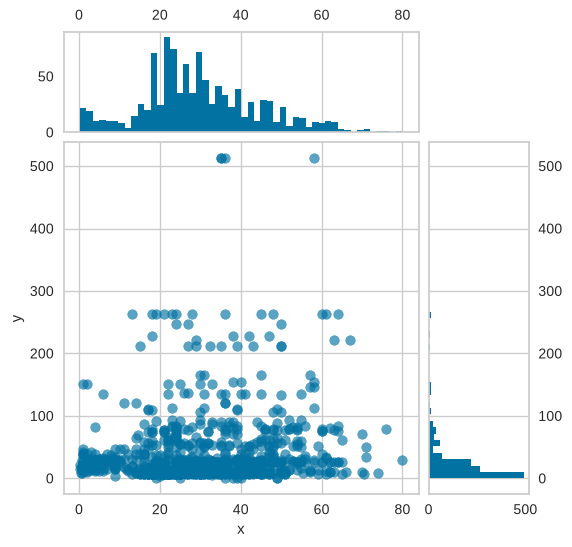

In [12]:
from yellowbrick.features import JointPlotVisualizer

fig, ax = plt.subplots(figsize=(6,6))

jpv = JointPlotVisualizer(feature="age", target="fare")

jpv.fit(X["age"], X["fare"])
fig.savefig("images/006-joinplotvisualizer.png", dpi=300)

## Boxplot y violinplot

boxplot y biolinplot ayudan a visualizar la distribución de una variable con respecto a un target

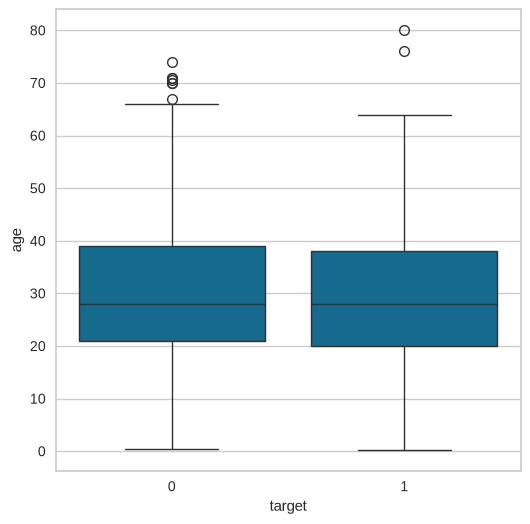

In [13]:
from seaborn import boxplot

new_df = X.copy()
new_df["target"] = y

fig, ax = plt.subplots(figsize=(6,6))

# x representa el eje horizontal
# y representa el eje vertical
# "age" en función del target
boxplot(x="target", y="age", data=new_df)

fig.savefig("images/006-boxplot.png", dpi=300)

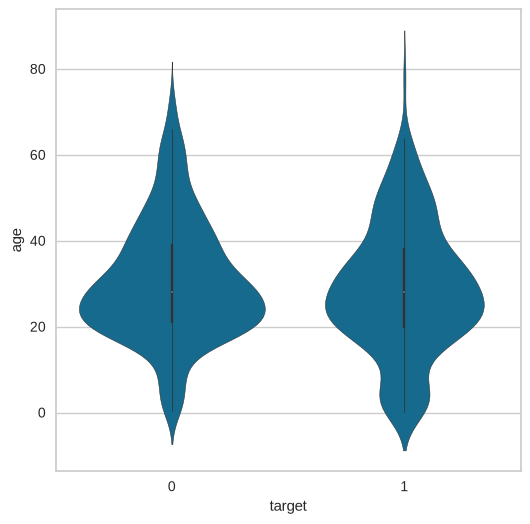

In [14]:
from seaborn import violinplot

new_dfv = X.copy()
new_dfv["target"] = y

fig, ax = plt.subplots(figsize=(6,6))

violinplot(x="target", y="age", data=new_dfv)
fig.savefig("images/006-violinplot.png", dpi=300)

# Correlación

Un grafico de correlación permite identificar variables que tengan relación  de modo que podamos ver pistas de forma visual. En yellowbrick contamos con Rank2D, mientras que seaborn ofrece heatmap

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

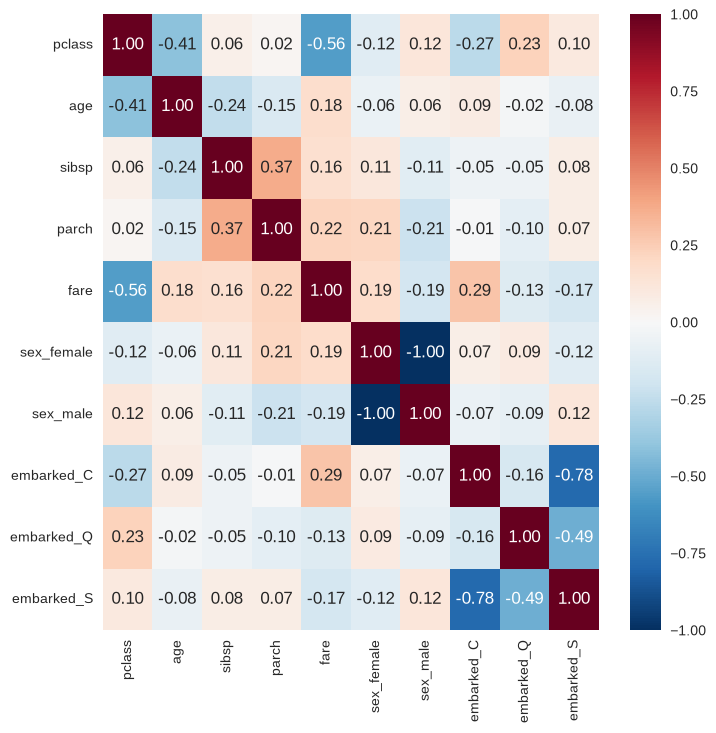

In [18]:
fig, ax = plt.subplots(figsize=(8,8))

ht = sns.heatmap(
    X.corr(),
    fmt=".2f",
    annot=True,
    ax=ax,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

fig.savefig("images/heatmap.png", dpi=300)

In [19]:
X.corr().iloc[:, :2]

,pclass,age
pclass,1.000000,-0.408106
age,-0.408106,1.000000
sibsp,0.060832,-0.243699
parch,0.018322,-0.150917
fare,-0.558629,0.178739
sex_female,-0.124617,-0.063646
sex_male,0.124617,0.063646
embarked_C,-0.269658,0.085777
embarked_Q,0.230491,-0.019458
embarked_S,0.096335,-0.075971
